Imports & Environment Setup

In [1]:
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
print("TensorFlow loaded safely.")
import shutil
from sklearn.metrics import roc_auc_score, precision_score, recall_score




TensorFlow loaded safely.


Load the Three Trained Models

In [2]:
model_sources = {
    "Baseline MobileNetV2": r"C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\mlruns\801261189415056438\394d4c1005014d1fad4cfc34b77274a8\artifacts\model\data\model",
    "ResNet50 Multimodal": r"C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\mlruns\575836104107197782\33cc2abbc0cd44d2a74b029ec9adbcf9\artifacts\model\data\model",
    "Research EfficientNetB0": r"C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\mlruns\148737279001566447\0539c85af95a451484e63eeb9338dc29\artifacts\model\data\model"
}

dest_root = r"C:\clean_models"
os.makedirs(dest_root, exist_ok=True)

models_dict = {}

for name, src_path in model_sources.items():
    safe_name = name.lower().replace(" ", "_")
    dest_path = os.path.join(dest_root, safe_name)
    
    print(f"[*] Processing: {name}")
    
    # Check if the clean folder already has the model files
    model_file_check = os.path.join(dest_path, "saved_model.pb")
    
    if not os.path.exists(model_file_check):
        try:
            print(f"    -> First time setup: Copying to clean path ({dest_path})...")
            if os.path.exists(dest_path):
                shutil.rmtree(dest_path)
            shutil.copytree(src_path, dest_path)
        except Exception as e:
            print(f"[-] Error copying {name}: {e}\n")
            continue
    else:
        print(f"    -> Cached copy found! Skipping copy step.")
        
    try:
        print(f"    -> Loading model into memory...")
        models_dict[name] = tf.keras.models.load_model(dest_path)
        print(f"[+] Successfully loaded {name}!\n")
    except Exception as e:
        print(f"[-] Error loading {name}: {e}\n")

print(f"Done! Successfully loaded {len(models_dict)} out of 3 models.")

[*] Processing: Baseline MobileNetV2
    -> Cached copy found! Skipping copy step.
    -> Loading model into memory...



[+] Successfully loaded Baseline MobileNetV2!

[*] Processing: ResNet50 Multimodal
    -> Cached copy found! Skipping copy step.
    -> Loading model into memory...
[+] Successfully loaded ResNet50 Multimodal!

[*] Processing: Research EfficientNetB0
    -> Cached copy found! Skipping copy step.
    -> Loading model into memory...
[+] Successfully loaded Research EfficientNetB0!

Done! Successfully loaded 3 out of 3 models.


Load Test Sample Data

In [3]:
# Load test metadata and ground truth to pick a sample (e.g., a malignant case)
CSV_PATH = r"C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\metadata_preprocessed.csv"
GT_PATH = r"C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\ISIC_2024_Training_GroundTruth.csv"
IMG_DIR = r"C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\images"

df_meta = pd.read_csv(CSV_PATH)
df_gt = pd.read_csv(GT_PATH)
df = pd.merge(df_meta, df_gt, on="isic_id", how="inner")

# Pick a confirmed malignant sample for high-risk visualization
sample_row = df[df["malignant"] == 1].iloc[0]
isic_id = sample_row["isic_id"]
true_label = sample_row["malignant"]

# Prepare Image
img_path = os.path.join(IMG_DIR, f"{isic_id}.jpg")
pil_img = Image.open(img_path).convert("RGB").resize((109, 109))
img_array = np.array(pil_img) / 255.0
img_tensor = np.expand_dims(img_array, axis=0)

# Prepare Tabular Features (46 features)
# Prepare Tabular Features (Safely dropping IDs/targets and coercing text to numeric)
features_series = sample_row.drop(columns=["isic_id", "patient_id", "malignant"], errors="ignore")

# Convert to numeric, replace any unconvertible strings with 0, and cast to float32
tab_features = pd.to_numeric(features_series, errors='coerce').fillna(0).values.astype(np.float32)

# Ensure it matches your model's expected 46-feature shape
if len(tab_features) != 46:
    if len(tab_features) > 46:
        tab_features = tab_features[:46]
    else:
        tab_features = np.pad(tab_features, (0, 46 - len(tab_features)), 'constant')

tab_tensor = np.expand_dims(tab_features, axis=0)

print(f"Loaded Sample ID: {isic_id} | True Label: {'Malignant (1)' if true_label == 1 else 'Benign (0)'}")

Loaded Sample ID: ISIC_0082829 | True Label: Malignant (1)


Grad-CAM Function for Multimodal Models

In [4]:
def make_gradcam_heatmap(img_array_batch, tab_array_batch, model, cnn_layer_name):
    """Computes Grad-CAM heatmap focusing on the CNN image backbone."""
    # Build a sub-model that maps image input to the target conv layer output and final prediction
    # (Handling multimodal input requires tracing gradients through the image branch)
    try:
        # Extract the image backbone submodel
        backbone = model.get_layer('efficientnetb0') # Update layer name if using MobileNetV2/ResNet50
        last_conv_layer = backbone.get_layer(cnn_layer_name)
    except Exception:
        # Fallback if layer name differs
        return np.zeros((109, 109))

    grad_model = tf.keras.models.Model(
        inputs=model.inputs, 
        outputs=[last_conv_layer.output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model([img_array_batch, tab_array_batch])
        loss = predictions[:, 0] # Malignant output node

    # Extract gradients of the output with respect to the last conv layer
    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    
    # Normalize heatmap between 0 and 1
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

Run Predictions & Generate Comparison Visualization

1/1 [==============================] - 2s 2s/step


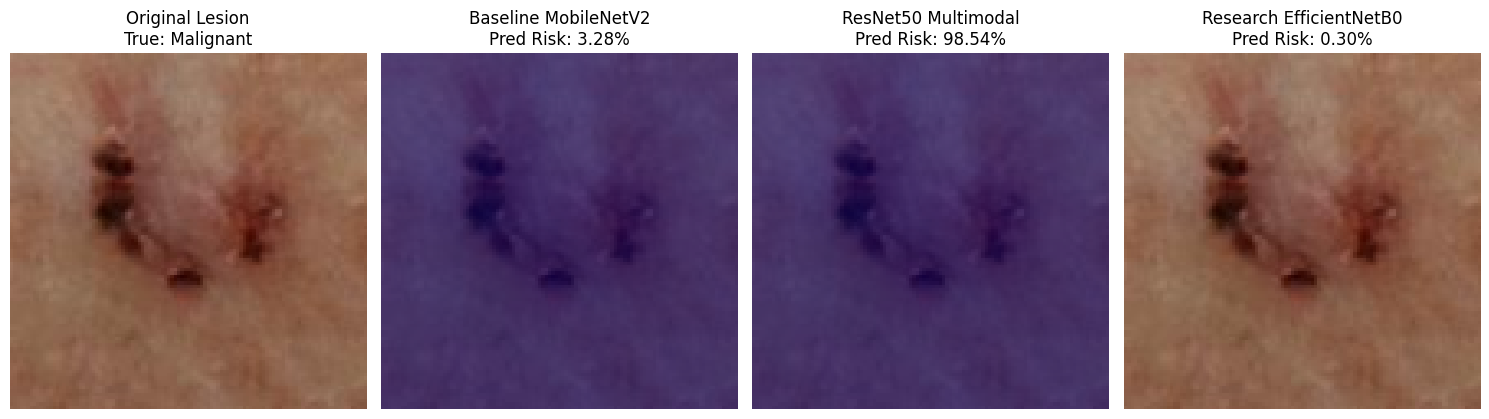

In [5]:
fig, axes = plt.subplots(1, len(models_dict) + 1, figsize=(15, 5))

# 1. Show Original Image
axes[0].imshow(pil_img)
axes[0].set_title(f"Original Lesion\nTrue: {'Malignant' if true_label==1 else 'Benign'}")
axes[0].axis("off")

# 2. Iterate through models, predict probability, and plot
for idx, (name, mdl) in enumerate(models_dict.items(), start=1):
    # Predict probability
    pred_prob = float(mdl.predict([img_tensor, tab_tensor])[0][0])
    
    # Generate Heatmap (using EfficientNet's top conv layer 'top_conv' as default)
    try:
        heatmap = make_gradcam_heatmap(img_tensor, tab_tensor, mdl, 'top_conv')
        heatmap_resized = Image.fromarray(np.uint8(255 * heatmap)).resize((109, 109), Image.BILINEAR)
        
        axes[idx].imshow(pil_img)
        axes[idx].imshow(heatmap_resized, cmap='jet', alpha=0.5) # Overlay Grad-CAM
    except Exception as e:
        axes[idx].imshow(pil_img) # Fallback if layer name mismatches
        
    axes[idx].set_title(f"{name}\nPred Risk: {pred_prob:.2%}")
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

Quantitative Comparison Table (Test Set Metrics)

In [6]:
from sklearn.metrics import roc_auc_score, precision_score, recall_score

# Load full test set using your helper function
from model_training_helper_codes import load_multimodal_datasets
_, test_ds = load_multimodal_datasets(test_size=500) # Fast evaluation batch

metrics_summary = []

for name, mdl in models_dict.items():
    y_true = []
    y_pred_probs = []
    
    for batch in test_ds:
        # Robustly unpack inputs and labels based on tf.data structure
        if len(batch) == 2:
            inputs, labels = batch
        else:
            raise ValueError("Unexpected dataset batch structure.")
            
        # Predict using the multimodal inputs list [images, tabular]
        preds = mdl.predict(inputs, verbose=0).flatten()
        y_pred_probs.extend(preds)
        
        # Handle labels (whether tensor or numpy)
        if hasattr(labels, "numpy"):
            y_true.extend(labels.numpy())
        else:
            y_true.extend(labels)
        
    y_true = np.array(y_true)
    y_pred_probs = np.array(y_pred_probs)
    y_pred_binary = (y_pred_probs >= 0.4).astype(int)
    
    auc = roc_auc_score(y_true, y_pred_probs)
    precision = precision_score(y_true, y_pred_binary, zero_division=0)
    recall = recall_score(y_true, y_pred_binary, zero_division=0)
    
    metrics_summary.append({
        "Model": name,
        "AUC-ROC": round(auc, 4),
        "Precision": round(precision, 4),
        "Recall (Sensitivity)": round(recall, 4)
    })

df_metrics = pd.DataFrame(metrics_summary)
display(df_metrics)

[+] Loading metadata and ground truth labels...
[+] Verifying image assets on disk...
[+] Valid samples with verified images: 68091
[+] Train set: 8000 samples | Malignant ratio: 2.39%
[+] Test set: 500 samples | Malignant ratio: 5.00%


,Model,AUC-ROC,Precision,Recall (Sensitivity)
0,Baseline MobileNetV2,0.8605,1.0,0.04
1,ResNet50 Multimodal,0.9197,0.6,0.36
2,Research EfficientNetB0,0.9325,1.0,0.08


Ensemble Voting System

In [10]:
from sklearn.metrics import roc_auc_score, precision_score, recall_score

# Cell 7: Ensemble Voting Evaluation (Union & Majority Vote)

y_true_all = []
preds_dict = {}

# Initialize dictionary keys for each model in models_dict
for name in models_dict.keys():
    preds_dict[name] = []

# Collect predictions across the test set from all 3 models
for batch in test_ds:
    inputs, labels = batch
    for name, mdl in models_dict.items():
        preds = mdl.predict(inputs, verbose=0).flatten()
        preds_dict[name].extend(preds)
        
    if hasattr(labels, "numpy"):
        y_true_all.extend(labels.numpy())
    else:
        y_true_all.extend(labels)

y_true_all = np.array(y_true_all)

# Extract arrays for each model
model_names = list(models_dict.keys())
p1 = np.array(preds_dict[model_names[0]])
p2 = np.array(preds_dict[model_names[1]])
p3 = np.array(preds_dict[model_names[2]])

# Individual binary decisions (threshold = 0.4)
b1 = (p1 >= 0.3).astype(int)
b2 = (p2 >= 0.3).astype(int)
b3 = (p3 >= 0.3).astype(int)

# --- Strategy 1: Union (Any model says malignant -> Final verdict Malignant) ---
# For AUC, use the maximum predicted risk among the 3 models
prob_union = np.maximum(np.maximum(p1, p2), p3)
bin_union = np.maximum(np.maximum(b1, b2), b3)

# --- Strategy 2: Majority Vote (At least 2 out of 3 models agree) ---
# For AUC, use the average probability across the 3 models
prob_majority = (p1 + p2 + p3) / 3.0
bin_majority = ((b1 + b2 + b3) >= 2).astype(int)

# Calculate metrics for Union
auc_union = roc_auc_score(y_true_all, prob_union)
prec_union = precision_score(y_true_all, bin_union, zero_division=0)
rec_union = recall_score(y_true_all, bin_union, zero_division=0)

# Calculate metrics for Majority Vote
auc_maj = roc_auc_score(y_true_all, prob_majority)
prec_maj = precision_score(y_true_all, bin_majority, zero_division=0)
rec_maj = recall_score(y_true_all, bin_majority, zero_division=0)

# Display comparative ensemble summary table
ensemble_summary = [
    {
        "Ensemble Strategy": "Union (Any Model Flagged / Max Risk)",
        "AUC-ROC": round(auc_union, 4),
        "Precision": round(prec_union, 4),
        "Recall (Sensitivity)": round(rec_union, 4)
    },
    {
        "Ensemble Strategy": "Majority Vote (>= 2 Models Agree)",
        "AUC-ROC": round(auc_maj, 4),
        "Precision": round(prec_maj, 4),
        "Recall (Sensitivity)": round(rec_maj, 4)
    }
]

df_ensemble = pd.DataFrame(ensemble_summary)
display(df_ensemble)

,Ensemble Strategy,AUC-ROC,Precision,Recall (Sensitivity)
0,Union (Any Model Flagged / Max Risk),0.9401,0.6111,0.44
1,Majority Vote (>= 2 Models Agree),0.9581,0.6667,0.08
